In [81]:
import glob
import os
import time
import warnings

import cv2
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from skimage.feature import graycomatrix, graycoprops
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC

In [82]:
warnings.filterwarnings("ignore")

In [83]:
DATASET_DIR = "datasets"
IMG_SIZE = (256, 256)
LEVELS = 64
DISTANCE = [1, 2, 3]
ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
PROPS = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]

In [84]:
records = []

for dataset in os.listdir(DATASET_DIR):
    dataset_path = os.path.join(DATASET_DIR, dataset)
    if not os.path.isdir(dataset_path):
        continue

    img_files = []
    for extension in ("*.png", "*.jpg", "*.jpeg"):
        img_files.extend(glob.glob(os.path.join(dataset_path, extension)))

    for img_file in img_files:
        img = cv2.imread(img_file, cv2.IMREAD_GRAYSCALE)
        if img is None:
            raise ValueError(f"Gagal membaca gambar: {img_file}")

        img_resized = cv2.resize(img, IMG_SIZE)
        img_quantized = (img_resized.astype(np.uint16) * LEVELS // 256).astype(np.uint8)

        glcm = graycomatrix(
            img_quantized,
            distances=DISTANCE,
            angles=ANGLES,
            levels=LEVELS,
            symmetric=True,
            normed=True,
        )

        record = {"dataset": dataset, "image": img_file}
        for prop in PROPS:
            values = graycoprops(glcm, prop)
            for distance_idx, distance in enumerate(DISTANCE):
                for angle_idx, angle in enumerate(ANGLES):
                    column = f"{prop}_d{distance}_a{angle:.4f}"
                    record[column] = values[distance_idx, angle_idx]
        records.append(record)

df = pd.DataFrame.from_records(records)
if df.empty:
    raise ValueError(f"Tidak ada gambar yang ditemukan di {DATASET_DIR}")

df.to_csv("glcm_features.csv", index=False)

print(df.shape)
print(df["dataset"].value_counts())


(151, 74)
dataset
Yosia    51
Felix    50
Eric     50
Name: count, dtype: int64


In [85]:
df = pd.read_csv("glcm_features.csv")

In [86]:
df.shape
df.info()
df.dtypes

<class 'pandas.DataFrame'>
RangeIndex: 151 entries, 0 to 150
Data columns (total 74 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   dataset                   151 non-null    str    
 1   image                     151 non-null    str    
 2   contrast_d1_a0.0000       151 non-null    float64
 3   contrast_d1_a0.7854       151 non-null    float64
 4   contrast_d1_a1.5708       151 non-null    float64
 5   contrast_d1_a2.3562       151 non-null    float64
 6   contrast_d2_a0.0000       151 non-null    float64
 7   contrast_d2_a0.7854       151 non-null    float64
 8   contrast_d2_a1.5708       151 non-null    float64
 9   contrast_d2_a2.3562       151 non-null    float64
 10  contrast_d3_a0.0000       151 non-null    float64
 11  contrast_d3_a0.7854       151 non-null    float64
 12  contrast_d3_a1.5708       151 non-null    float64
 13  contrast_d3_a2.3562       151 non-null    float64
 14  dissimilarity_d1_a0.0

dataset                    str
image                      str
contrast_d1_a0.0000    float64
contrast_d1_a0.7854    float64
contrast_d1_a1.5708    float64
                        ...   
ASM_d2_a2.3562         float64
ASM_d3_a0.0000         float64
ASM_d3_a0.7854         float64
ASM_d3_a1.5708         float64
ASM_d3_a2.3562         float64
Length: 74, dtype: object

In [87]:
count_imbalance = df["dataset"].value_counts()
print(count_imbalance)

dataset
Yosia    51
Felix    50
Eric     50
Name: count, dtype: int64


In [88]:
encoder = LabelEncoder()
y = encoder.fit_transform(df["dataset"])

In [89]:
X = df.drop(columns=["dataset", "image"])
y = encoder.fit_transform(df["dataset"])

In [90]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

In [91]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [92]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

In [93]:
PARAMS_SVM = {
    "C": [0.1, 1, 10],
    "kernel": ["linear", "rbf", "poly"],
    "gamma": ["scale", "auto"],
    "class_weight": [None, "balanced"],
}

PARAM_XGB = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.1, 0.2],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "gamma": [0, 0.1, 0.2],
    "reg_alpha": [0, 0.1, 0.5],
    "reg_lambda": [1, 1.5, 2],
}

PARAM_LGBM = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.1, 0.2],
    "num_leaves": [31, 50, 100],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "reg_alpha": [0, 0.1, 0.5],
    "reg_lambda": [1, 1.5, 2],
}

In [94]:
models = {
    "SVM": (SVC(), PARAMS_SVM),
    "XGB": (xgb.XGBClassifier(verbosity=0), PARAM_XGB),
    "LGBM": (lgb.LGBMClassifier(verbosity=-1), PARAM_LGBM),
}

In [95]:
results = {}

for model_name, (model, params) in models.items():
    model_start_time = time.perf_counter()
    grid_search = RandomizedSearchCV(
        estimator=model,
        param_distributions=params,
        n_iter=10,
        scoring="accuracy",
        cv=cv,
        verbose=0,
        n_jobs=1,
        random_state=42,
    )
    grid_search.fit(X_scaled, y_train)
    training_time = time.perf_counter() - model_start_time
    best_model = grid_search.best_estimator_
    best_params = grid_search.best_params_
    best_score = grid_search.best_score_

    results[model_name] = {
        "best_model": best_model,
        "best_params": best_params,
        "best_score": best_score,
        "training_time_seconds": training_time,
    }


,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Waktu training + pencarian (detik)
Model,,,,,
SVM,1.0000,1.0000,1.0000,1.0000,0.13
XGB,0.9677,0.9697,0.9697,0.9683,14.49
LGBM,0.9677,0.9697,0.9697,0.9683,1.24


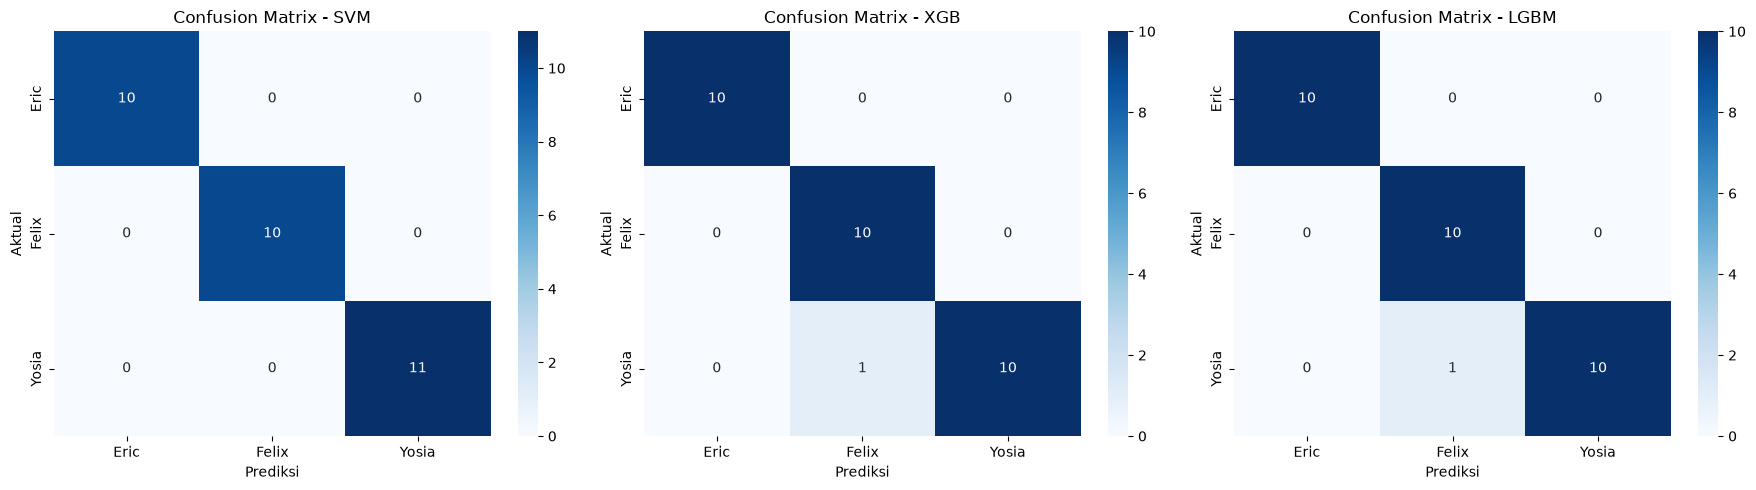

In [96]:
X_test_scaled = scaler.transform(X_test)
evaluation_rows = []

for model_name, result in results.items():
    y_pred = result["best_model"].predict(X_test_scaled)
    evaluation_rows.append(
        {
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision (macro)": precision_score(
                y_test, y_pred, average="macro", zero_division=0
            ),
            "Recall (macro)": recall_score(
                y_test, y_pred, average="macro", zero_division=0
            ),
            "F1-score (macro)": f1_score(
                y_test, y_pred, average="macro", zero_division=0
            ),
            "Waktu training + pencarian (detik)": result["training_time_seconds"],
        }
    )

comparison = pd.DataFrame(evaluation_rows).set_index("Model")
display(
    comparison.round(
        {
            "Accuracy": 4,
            "Precision (macro)": 4,
            "Recall (macro)": 4,
            "F1-score (macro)": 4,
            "Waktu training + pencarian (detik)": 2,
        }
    )
)

fig, axes = plt.subplots(1, len(results), figsize=(6 * len(results), 5))
if len(results) == 1:
    axes = [axes]

for ax, (model_name, result) in zip(axes, results.items()):
    y_pred = result["best_model"].predict(X_test_scaled)
    matrix = confusion_matrix(y_test, y_pred, labels=np.arange(len(encoder.classes_)))
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=encoder.classes_,
        yticklabels=encoder.classes_,
        ax=ax,
    )
    ax.set_title(f"Confusion Matrix - {model_name}")
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")

plt.tight_layout()
plt.show()